# MachineEar — 02 · Détection d’anomalies (Isolation Forest)

**But :** construire une baseline sur les caractéristiques acoustiques extraites des fichiers MIMII `0_dB_fan/id_00`. Entraînement sur les audios normaux uniquement ; seuil réglé sur validation ; évaluation finale sur un test indépendant.

> Les lignes du CSV sont des enregistrements de 10 s. Si plusieurs lignes proviennent d’une même session/enregistrement source, il faut les regrouper pour éviter les fuites entre jeux. Les chemins seuls ne prouvent pas l’indépendance des prises.

## 1 — Imports et chemins

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest
from sklearn.metrics import (roc_auc_score, average_precision_score, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report, roc_curve,
                             precision_recall_curve)
import joblib

SEED = 42
PROJECT_DIR = Path.cwd().resolve()
if PROJECT_DIR.name == "notebooks":
    PROJECT_DIR = PROJECT_DIR.parent
CSV_PATH = PROJECT_DIR / "data" / "processed" / "fan_id00_features.csv"
MODEL_DIR = PROJECT_DIR / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)
print("Projet :", PROJECT_DIR)
print("CSV :", CSV_PATH)
assert CSV_PATH.exists(), f"CSV introuvable : {CSV_PATH}. Vérifie le nom du fichier et le dossier data/processed."


Projet : C:\Users\0503506P\Downloads\MachineEar_VSCode\MachineEar
CSV : C:\Users\0503506P\Downloads\MachineEar_VSCode\MachineEar\data\processed\fan_id00_features.csv


## 2 — Vérifications et choix des variables
On exclut le chemin, l’étiquette et la durée (constante). Aucune information de la classe ne doit entrer dans les caractéristiques.

In [2]:
df = pd.read_csv(CSV_PATH)
assert "label" in df.columns, "Colonne label absente"
assert df["label"].notna().all(), "Labels manquants"
assert set(df["label"].unique()) == {0, 1}, "Les labels doivent être 0 (normal) et 1 (anormal)"
if "file_path" in df:
    assert not df["file_path"].duplicated().any(), "Chemins audio dupliqués"
excluded = {"label", "duration_sec", "file_path"}
feature_cols = [c for c in df.select_dtypes(include="number").columns if c not in excluded]
assert feature_cols, "Aucune caractéristique numérique détectée"
X = df[feature_cols].copy()
y = df["label"].astype(int)
assert np.isfinite(X.to_numpy(dtype=float)).all(), "NaN ou valeurs infinies détectées"
print("Dimensions :", df.shape, "| Variables utilisées :", len(feature_cols))
print("Classes :", y.value_counts().to_dict())
print("Variables :", feature_cols[:10], "...")


Dimensions : (1418, 55) | Variables utilisées : 52
Classes : {0: 1011, 1: 407}
Variables : ['mfcc_01_mean', 'mfcc_01_std', 'mfcc_02_mean', 'mfcc_02_std', 'mfcc_03_mean', 'mfcc_03_std', 'mfcc_04_mean', 'mfcc_04_std', 'mfcc_05_mean', 'mfcc_05_std'] ...


## 3 — Séparation train / validation / test
Le train contient **uniquement des sons normaux**. La validation comprend des sons normaux et anormaux pour sélectionner un seuil ; le test reste intact jusqu’à l’évaluation finale.

⚠️ Cette séparation aléatoire par fichier est une **baseline exploratoire**. Pour une évaluation scientifique robuste, utiliser des groupes de session/source si disponibles et, ensuite, tester sur d’autres identifiants de ventilateurs et niveaux de bruit.

In [3]:
normal_idx = df.index[y == 0].to_numpy()
abnormal_idx = df.index[y == 1].to_numpy()
# 60 % train, 20 % validation, 20 % test parmi les normaux
train_idx, holdout_normal = train_test_split(normal_idx, test_size=0.40, random_state=SEED)
val_normal, test_normal = train_test_split(holdout_normal, test_size=0.50, random_state=SEED)
# 50 % validation, 50 % test parmi les anormaux ; aucun anormal dans train
val_abnormal, test_abnormal = train_test_split(abnormal_idx, test_size=0.50, random_state=SEED)
val_idx = np.concatenate([val_normal, val_abnormal])
test_idx = np.concatenate([test_normal, test_abnormal])
assert not (set(train_idx) & set(val_idx) or set(train_idx) & set(test_idx) or set(val_idx) & set(test_idx))
print(f"Train : {len(train_idx)} normaux / 0 anormaux")
print(f"Validation : {len(val_normal)} normaux / {len(val_abnormal)} anormaux")
print(f"Test : {len(test_normal)} normaux / {len(test_abnormal)} anormaux")


Train : 606 normaux / 0 anormaux
Validation : 202 normaux / 203 anormaux
Test : 203 normaux / 204 anormaux


## 4 — Entraînement Isolation Forest
La standardisation est ajustée **sur le train seulement**, à l’intérieur du pipeline. Un score d’anomalie plus grand signifie un son plus inhabituel.

In [4]:
model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("detector", IsolationForest(n_estimators=300, max_samples="auto", contamination="auto",
                                 random_state=SEED, n_jobs=-1)),
])
model.fit(X.loc[train_idx])

def anomaly_score(data):
    # score_samples : plus élevé = plus normal ; inversion pour les anomalies
    z = model.named_steps["imputer"].transform(data)
    z = model.named_steps["scaler"].transform(z)
    return -model.named_steps["detector"].score_samples(z)

val_scores = anomaly_score(X.loc[val_idx])
val_labels = y.loc[val_idx].to_numpy()
print("ROC-AUC validation :", round(roc_auc_score(val_labels, val_scores), 4))
print("PR-AUC validation :", round(average_precision_score(val_labels, val_scores), 4))


ROC-AUC validation : 0.6509
PR-AUC validation : 0.6029


## 5 — Définition du seuil sur validation
Nous fixons ici un **taux maximal cible de fausses alertes de 5 %** parmi les sons normaux de validation. Le taux réellement observé sur le test peut être différent.

In [5]:
TARGET_FPR = 0.05
normal_val_scores = val_scores[val_labels == 0]
threshold = float(np.quantile(normal_val_scores, 1 - TARGET_FPR))
val_pred = (val_scores > threshold).astype(int)
val_cm = confusion_matrix(val_labels, val_pred, labels=[0, 1])
print(f"Seuil choisi sur validation : {threshold:.6f}")
print("Matrice validation [normal, anormal] :\n", val_cm)
print("FPR validation :", round(val_cm[0,1] / max(1,val_cm[0].sum()), 4))


Seuil choisi sur validation : 0.524354
Matrice validation [normal, anormal] :
 [[191  11]
 [188  15]]
FPR validation : 0.0545


## 6 — Évaluation finale sur le jeu de test
Ne pas ajuster le seuil après avoir regardé les résultats du test : cela biaiserait l’évaluation.

ROC-AUC test : 0.6733
PR-AUC test : 0.6216
Taux de fausses alertes (FPR) : 5.42%
Rappel des anomalies : 5.88%

Rapport de classification :
              precision    recall  f1-score   support

      Normal       0.50      0.95      0.65       203
     Anormal       0.52      0.06      0.11       204

    accuracy                           0.50       407
   macro avg       0.51      0.50      0.38       407
weighted avg       0.51      0.50      0.38       407



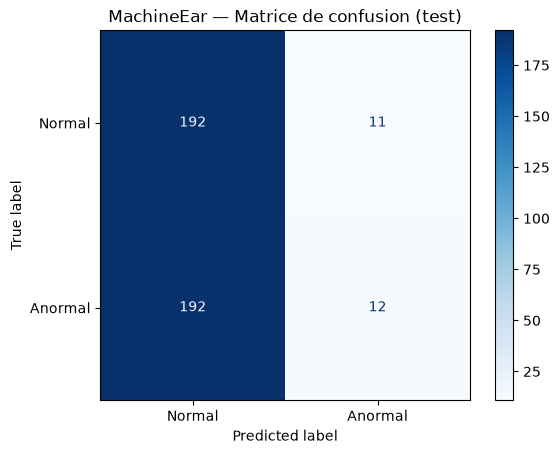

In [6]:
test_scores = anomaly_score(X.loc[test_idx])
test_labels = y.loc[test_idx].to_numpy()
test_pred = (test_scores > threshold).astype(int)
roc_auc = roc_auc_score(test_labels, test_scores)
pr_auc = average_precision_score(test_labels, test_scores)
cm = confusion_matrix(test_labels, test_pred, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()
print(f"ROC-AUC test : {roc_auc:.4f}")
print(f"PR-AUC test : {pr_auc:.4f}")
print(f"Taux de fausses alertes (FPR) : {fp / (fp + tn):.2%}")
print(f"Rappel des anomalies : {tp / (tp + fn):.2%}")
print("\nRapport de classification :")
print(classification_report(test_labels, test_pred, target_names=["Normal", "Anormal"], zero_division=0))
ConfusionMatrixDisplay(cm, display_labels=["Normal", "Anormal"]).plot(cmap="Blues", values_format="d")
plt.title("MachineEar — Matrice de confusion (test)")
plt.show()


## 7 — Courbes ROC et précision-rappel

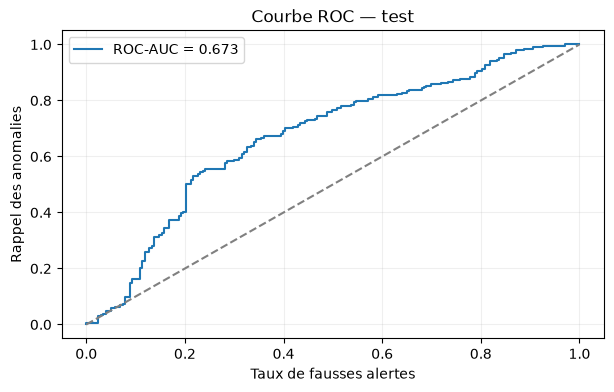

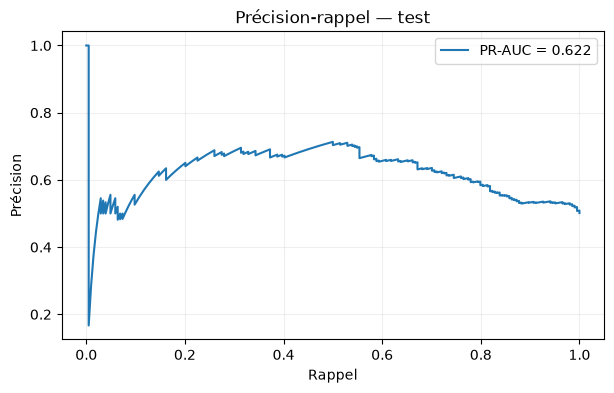

In [7]:
fpr, tpr, _ = roc_curve(test_labels, test_scores)
precision, recall, _ = precision_recall_curve(test_labels, test_scores)
plt.figure(figsize=(7, 4))
plt.plot(fpr, tpr, label=f"ROC-AUC = {roc_auc:.3f}")
plt.plot([0, 1], [0, 1], "--", color="gray")
plt.xlabel("Taux de fausses alertes")
plt.ylabel("Rappel des anomalies")
plt.title("Courbe ROC — test")
plt.legend(); plt.grid(alpha=0.2); plt.show()
plt.figure(figsize=(7, 4))
plt.plot(recall, precision, label=f"PR-AUC = {pr_auc:.3f}")
plt.xlabel("Rappel")
plt.ylabel("Précision")
plt.title("Précision-rappel — test")
plt.legend(); plt.grid(alpha=0.2); plt.show()


## 8 — Sauvegarder le modèle et les résultats
Les noms des variables, le seuil et les métriques sont sauvegardés pour la future application.

In [8]:
artifact = {
    "pipeline": model,
    "feature_columns": feature_cols,
    "threshold": threshold,
    "score_convention": "-IsolationForest.score_samples (plus grand = plus anormal)",
    "target_validation_fpr": TARGET_FPR,
}
model_path = MODEL_DIR / "isolation_forest_fan_id00.joblib"
joblib.dump(artifact, model_path)
metrics = {
    "n_train": int(len(train_idx)), "n_validation": int(len(val_idx)), "n_test": int(len(test_idx)),
    "roc_auc_test": float(roc_auc), "average_precision_test": float(pr_auc),
    "false_positive_rate_test": float(fp / (fp + tn)),
    "anomaly_recall_test": float(tp / (tp + fn)),
    "threshold": threshold,
    "confusion_matrix_test": cm.tolist(),
}
metrics_path = MODEL_DIR / "isolation_forest_fan_id00_metrics.json"
metrics_path.write_text(json.dumps(metrics, indent=2, ensure_ascii=False), encoding="utf-8")
print("Modèle sauvegardé :", model_path)
print("Métriques sauvegardées :", metrics_path)


Modèle sauvegardé : C:\Users\0503506P\Downloads\MachineEar_VSCode\MachineEar\models\isolation_forest_fan_id00.joblib
Métriques sauvegardées : C:\Users\0503506P\Downloads\MachineEar_VSCode\MachineEar\models\isolation_forest_fan_id00_metrics.json


## Et après ?
Comparer cette baseline avec un autoencodeur ou un modèle utilisant les spectrogrammes, puis tester la généralisation à d’autres ventilateurs et niveaux sonores. Ne pas interpréter un score d’anomalie comme un diagnostic de panne.

**Attention :** ne charger les fichiers `.joblib` qu’à partir de sources de confiance.